In [11]:
%pip install wget

from pathlib import Path
import os

os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")

import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "Tidak terdeteksi; pelatihan menggunakan CPU.")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")

    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"

print("Folder gambar:", image_dir)

Folder gambar: data/dataset/Images


In [13]:
nama_kelas = sorted(
    folder.name for folder in image_dir.iterdir()
    if folder.is_dir()
)

gambar, label = [], []

for kelas, nama in enumerate(nama_kelas):
    for path in sorted((image_dir / nama).glob("*.tif")):
        with Image.open(path) as img:
            img = img.convert("RGB").resize(
                IMG_SIZE,
                Image.Resampling.BILINEAR
            )
        gambar.append(np.asarray(img))
        label.append(kelas)

X = np.asarray(gambar, dtype="uint8")
y = np.asarray(label, dtype="int32")

del gambar

assert len(nama_kelas) == 21 and len(X) == 2100, \
    "Periksa kelengkapan dataset"

assert np.all(np.bincount(y) == 100), \
    "Setiap kelas seharusnya memiliki 100 gambar"

print("Bentuk data:", X.shape)
print("Kelas:", nama_kelas)

Bentuk data: (2100, 224, 224, 3)
Kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


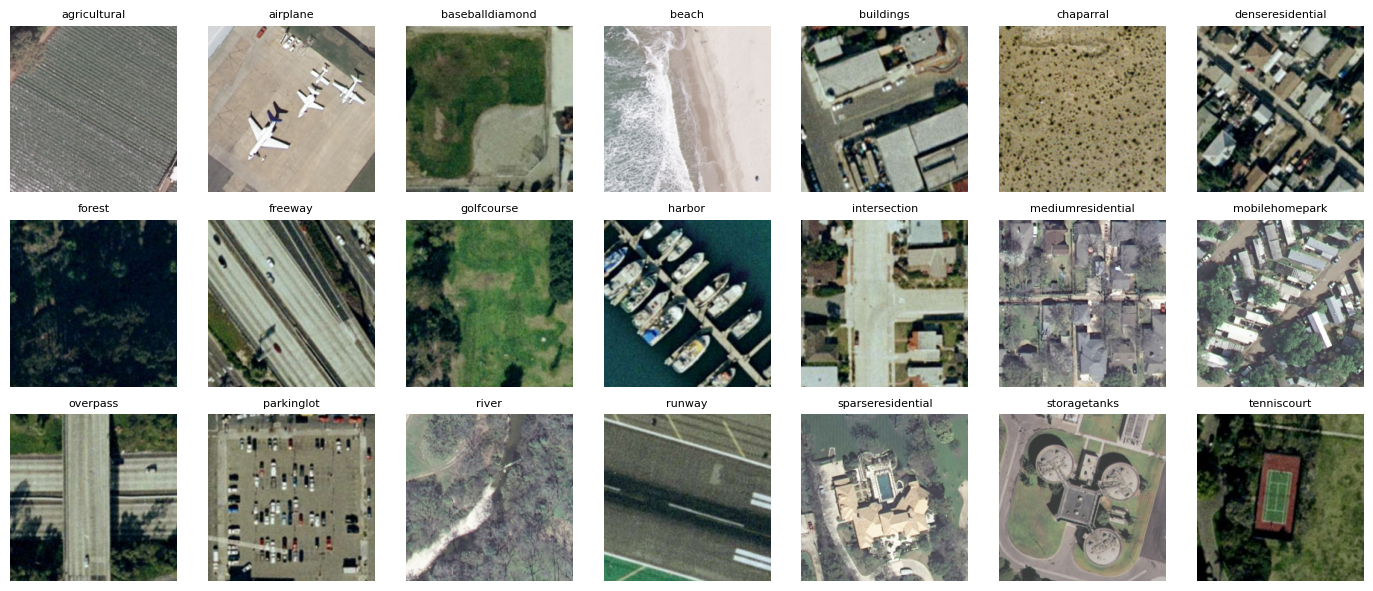

In [14]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))

for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
x_train, x_sisa, y_train, y_sisa = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_sisa,
    y_sisa,
    test_size=0.50,
    stratify=y_sisa,
    random_state=42
)

print(
    "Train:",
    len(y_train),
    "Validation:",
    len(y_val),
    "Test:",
    len(y_test)
)

Train: 1470 Validation: 315 Test: 315


In [16]:

# MODEL EFFICIENTNETB0

base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)

# Bekukan bobot pretrained
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

# EfficientNetB0 sudah memiliki preprocessing
# internal, jadi input tetap pada rentang 0-255
x = base_model(inputs, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="efficientnetb0_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "efficientnetb0_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 21)             │        26,901 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,076,472 (15.55 MB)

 Trainable params: 26,901 (105.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [17]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan:", len(history.history["loss"]))

Epoch 1/10
92/92 - 58s - 633ms/step - accuracy: 0.6095 - loss: 1.5662 - val_accuracy: 0.9079 - val_loss: 0.6132
Epoch 2/10
92/92 - 2s - 26ms/step - accuracy: 0.8925 - loss: 0.5326 - val_accuracy: 0.9460 - val_loss: 0.3465
Epoch 3/10
92/92 - 2s - 26ms/step - accuracy: 0.9388 - loss: 0.3353 - val_accuracy: 0.9556 - val_loss: 0.2522
Epoch 4/10
92/92 - 2s - 23ms/step - accuracy: 0.9544 - loss: 0.2424 - val_accuracy: 0.9619 - val_loss: 0.2057
Epoch 5/10
92/92 - 2s - 23ms/step - accuracy: 0.9639 - loss: 0.1967 - val_accuracy: 0.9524 - val_loss: 0.1800
Epoch 6/10
92/92 - 2s - 23ms/step - accuracy: 0.9721 - loss: 0.1607 - val_accuracy: 0.9619 - val_loss: 0.1573
Epoch 7/10
92/92 - 2s - 23ms/step - accuracy: 0.9830 - loss: 0.1316 - val_accuracy: 0.9683 - val_loss: 0.1423
Epoch 8/10
92/92 - 2s - 23ms/step - accuracy: 0.9796 - loss: 0.1163 - val_accuracy: 0.9619 - val_loss: 0.1342
Epoch 9/10
92/92 - 2s - 26ms/step - accuracy: 0.9844 - loss: 0.1003 - val_accuracy: 0.9683 - val_loss: 0.1252
Epoch 10

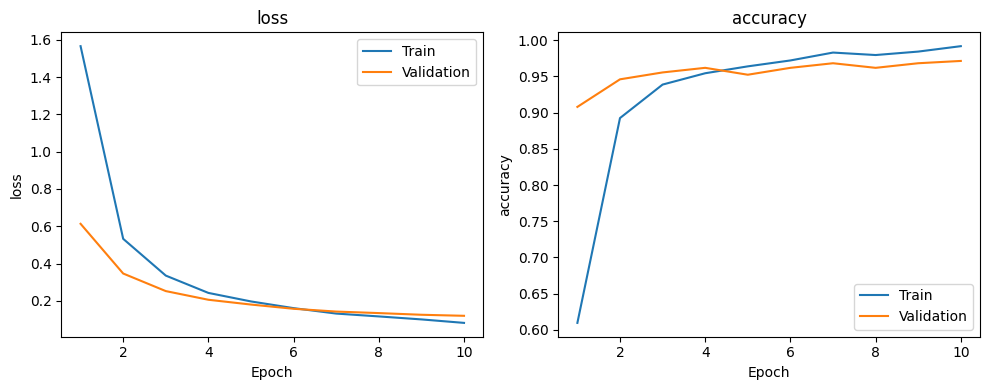

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss: 0.1685 | Test accuracy: 95.56%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       1.00      1.00      1.00        15
  baseballdiamond       1.00      1.00      1.00        15
            beach       1.00      1.00      1.00        15
        buildings       0.88      1.00      0.94        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.86      0.80      0.83        15
           forest       0.94      1.00      0.97        15
          freeway       1.00      1.00      1.00        15
       golfcourse       1.00      1.00      1.00        15
           harbor       1.00      1.00      1.00        15
     intersection       0.78      0.93      0.85        15
mediumresidential       0.86      0.80      0.83        15
   mobilehomepark       1.00      1.00      1.00        15
         overpass       1.00      0.87      0.93        15
       parkin

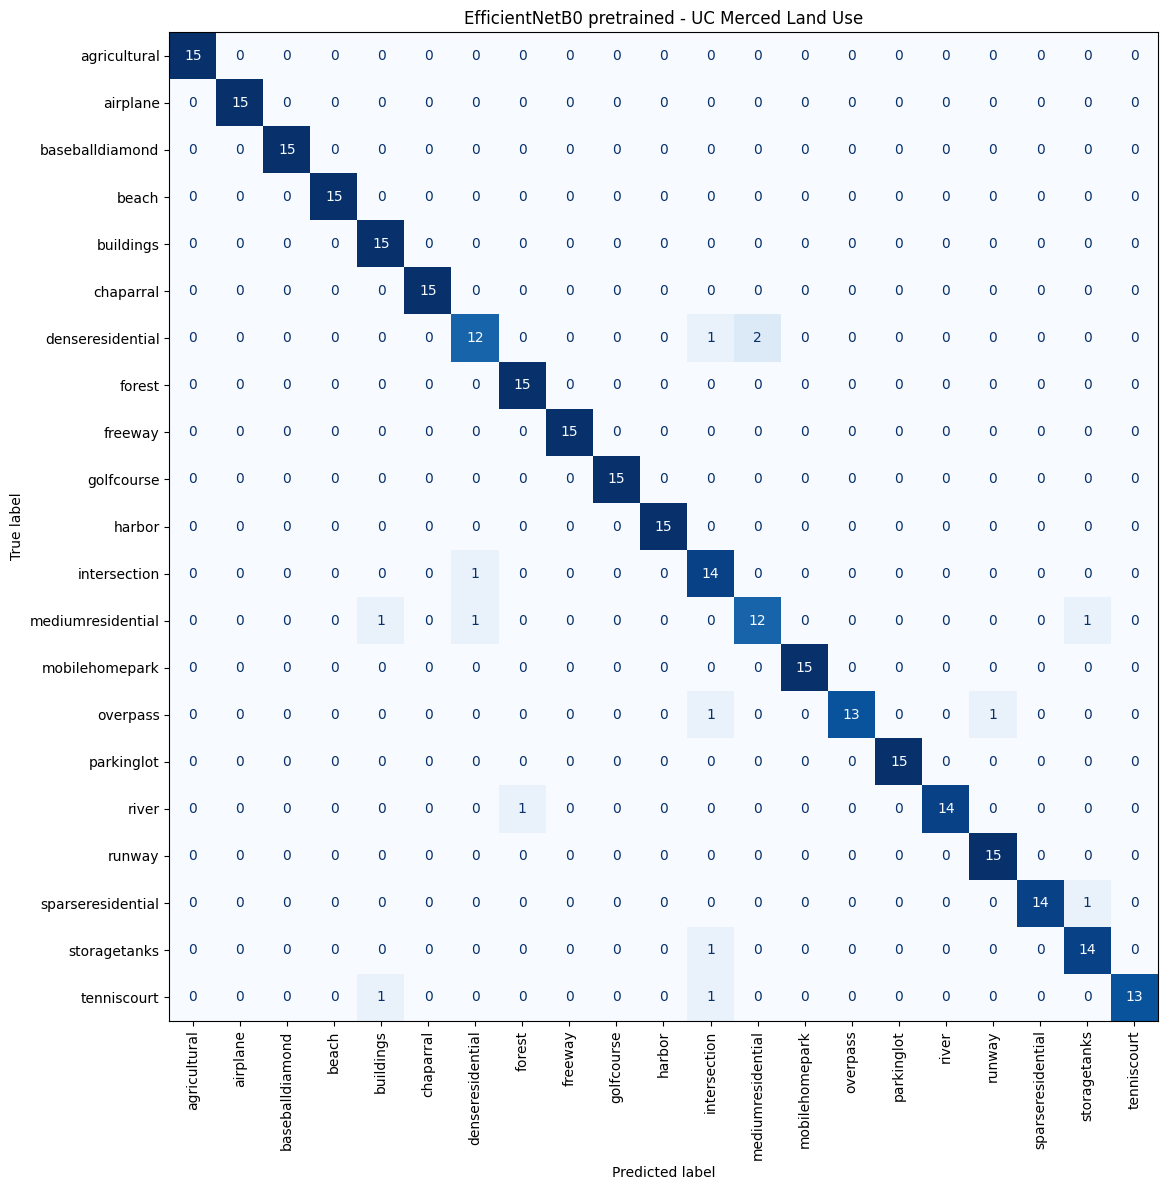

In [21]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss: {test_loss:.4f} | "
    f"Test accuracy: {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("EfficientNetB0 pretrained - UC Merced Land Use")

plt.tight_layout()
plt.show()

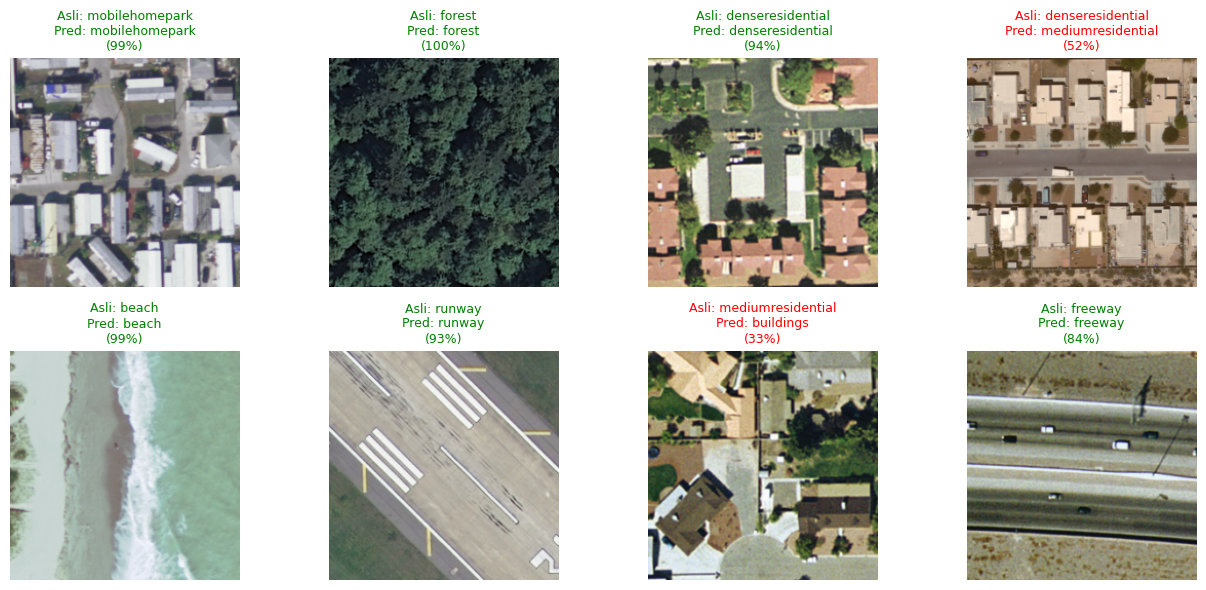

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]}\n"
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()